# Apprentissage semi-supervisé

**Projet :** BrainScanAI - détection semi-supervisée de tumeurs cérébrales  
**Étape :** 4 - Appliquez une méthode semi-supervisée  
**Auteur :** Kilian Lefevre

---

## Objectif du notebook

Les labels faibles de l'étape précédente permettent d'entraîner un CNN sur des centaines d'images non annotées. Ce notebook répond aux questions suivantes :

- Un CNN entraîné **d'abord sur les labels faibles, puis sur les labels forts**, détecte-t-il mieux les cancers qu'un CNN entraîné **sur les labels forts seuls** ?
- Que vaut un CNN entraîné sur les **labels faibles seuls**, et que montrent les **courbes d'apprentissage** de cette phase ?
- Quelles sont les limites de ce protocole ?

**Prérequis :** le manifeste dédupliqué (`data/interim/manifest.csv`), le découpage et les labels faibles (`data/processed/split.csv` et `weak_labels.csv`), produits par `make data` et par le notebook `03.01`.

## Les trois modèles comparés

| Modèle | Entraînement | Images d'entraînement |
|---|---|---|
| **A** - supervisé | labels forts | 68 images annotées |
| **B** - faible | labels faibles | 1 194 images non annotées |
| **C** - semi-supervisé | labels faibles, puis labels forts | 1 194, puis 68 images |

Les trois modèles partent du même **ResNet50 pré-entraîné sur ImageNet** (celui de l'extraction des features). `layer1` à `layer3` restent **gelées** ; `layer4` et la couche de classification sont **entraînées**. Ils sont évalués sur **les mêmes 15 images de test**, jamais vues pendant l'entraînement. Le modèle C **poursuit** l'entraînement de B sur les labels forts.

## Réglages et métriques

Tous les réglages sont **fixés d'avance** (section 1) et **jamais ajustés** : le test ne contient que 15 images, et chercher de bons réglages sur si peu d'images reviendrait à les ajuster sur le test.

L'erreur la plus grave est un `cancer` non détecté (faux négatif). La métrique principale est donc le **rappel de la classe `cancer`**, quitte à perdre un peu de précision. Les autres mesures complètent la lecture :

- la **précision** de la classe `cancer` ;
- le **F1 macro**, moyenne des F1 des deux classes, comme mesure globale d'arbitrage ;
- l'**exactitude** ;
- la **matrice de confusion** et le rapport de classification par classe.

Elles sont calculées au seuil de 0,5 : une image reçoit la classe la plus probable.

Avec 15 images de test, une image change la plupart de ces valeurs de plusieurs points : les écarts de quelques points ne sont pas significatifs.

## 1. Chargement et réglages

On charge le manifeste, le découpage et les labels faibles écrits par l'étape précédente. Les réglages de l'entraînement sont définis dans `brain_mri.modeling.train` :

| Réglage | Valeur |
|---|---|
| Optimiseur | Adam, taux d'apprentissage de 1e-4 |
| Taille des lots | 16 images |
| Phase sur les labels faibles | 10 époques fixes, sans arrêt anticipé |
| Phase sur les labels forts | 30 époques au plus, arrêt après 5 époques sans baisse de la perte de validation |
| Modèle conservé (labels forts) | celui de la **meilleure perte de validation** |
| Tirage des lots faibles | équilibré entre `cancer` et `normal` |
| Augmentation (entraînement) | retournement horizontal, rotation jusqu'à 15°, translation de 5 %, zoom de 5 % |

La phase sur les labels faibles n'a **pas d'arrêt anticipé** : la validation y est seulement **mesurée** à chaque époque, pour tracer les courbes, et ne sert pas à choisir l'époque. La validation (14 images) ne sert, ailleurs, qu'à l'arrêt anticipé de la phase sur les labels forts.

In [1]:
from copy import deepcopy

from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
import torch

from brain_mri.config import (
    FIGURES_DIR,
    INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR,
    SEED,
    set_seed,
)
from brain_mri.dataset import read_manifest, read_split
from brain_mri.features import MODEL_NAME, preprocess_gray, select_device
from brain_mri.modeling.train import (
    AUGMENT,
    DECISION_THRESHOLD,
    LEARNING_RATE,
    MAX_EPOCHS,
    PATIENCE,
    TRAIN_BATCH_SIZE,
    WEAK_EPOCHS,
    LabeledImages,
    classification_scores,
    count_parameters,
    create_model,
    fit,
    make_loader,
    predict,
)
from brain_mri.modeling.unsupervised import CLASS_CODES, encode_labels
from utils.mlflow_utils import (
    log_dataset,
    log_figure,
    log_metrics,
    log_params,
    log_pytorch_model,
    setup_mlflow,
    start_run,
)

pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

NOTEBOOK = "03.02-kl-semi-supervised"
MANIFEST_PATH = INTERIM_DATA_DIR / "manifest.csv"

# Graine d'entraînement.
TRAINING_SEED = SEED

# Noms, couleurs et libellés pour les tableaux et les figures.
CONDITIONS = {
    "A": "supervisé (labels forts)",
    "B": "faible (labels faibles)",
    "C": "semi-supervisé (faibles puis forts)",
}
CONDITION_COLORS = {"A": "#4C78A8", "B": "#BAB0AC", "C": "#E45756"}
METRIC_LABELS = {
    "recall": "Rappel (cancer)",
    "precision": "Précision (cancer)",
    "f1_macro": "F1 macro",
    "accuracy": "Exactitude",
}
print(f"Suivi MLflow : {setup_mlflow()}")
DEVICE = select_device()
print(f"Calcul sur {DEVICE}")

Suivi MLflow : sqlite:///<PROJECT_ROOT>/mlflow.db
Calcul sur mps


## 2. Les jeux d'entraînement, de validation et de test

Le découpage est celui de l'étape précédente (`data/processed/split.csv`) :

- l'**entraînement fort** regroupe les images annotées de l'entraînement ;
- l'**entraînement faible** regroupe les images non annotées, avec le label faible attribué par K-Means (`data/processed/weak_labels.csv`) ;
- la **validation** et le **test** sont des images annotées, absentes de l'entraînement.

Le code des classes est le même qu'à l'étape précédente : 1 pour `cancer`, 0 pour `normal`.

In [2]:
manifest = read_manifest(MANIFEST_PATH)
split = read_split(PROCESSED_DATA_DIR / "split.csv")
assert (split["image_id"] == manifest["image_id"]).all()
manifest["split"] = split["split"].to_numpy()

weak_table = pd.read_csv(
    PROCESSED_DATA_DIR / "weak_labels.csv", dtype={"image_id": str}
)
strong_label = encode_labels(manifest["label"])
is_labeled = manifest["is_labeled"].to_numpy()

# Label faible de chaque image du manifeste (NaN pour les images annotées).
weak_codes = weak_table.set_index("image_id")["weak_label"].map(CLASS_CODES)
weak_label = manifest["image_id"].map(weak_codes).to_numpy(dtype=float)

split_values = manifest["split"].to_numpy()
indices = {
    "strong": np.flatnonzero((split_values == "train") & is_labeled),
    "weak": np.flatnonzero((split_values == "train") & ~is_labeled),
    "validation": np.flatnonzero(split_values == "validation"),
    "test": np.flatnonzero(split_values == "test"),
}


def describe(positions, labels):
    """Effectifs d'un jeu : images, `cancer` et `normal`."""
    codes = labels[positions]
    return {
        "images": len(positions),
        "cancer": int((codes == 1).sum()),
        "normal": int((codes == 0).sum()),
    }


display(
    pd.DataFrame(
        {
            "Entraînement fort (labels forts)": describe(
                indices["strong"], strong_label
            ),
            "Entraînement faible (labels faibles)": describe(
                indices["weak"], weak_label
            ),
            "Validation (labels forts)": describe(
                indices["validation"], strong_label
            ),
            "Test (labels forts)": describe(indices["test"], strong_label),
        }
    ).T
)

all_positions = np.concatenate(list(indices.values()))
assert len(all_positions) == len(set(all_positions)), "jeux non disjoints"
assert np.isnan(strong_label[indices["weak"]]).all()
assert not np.isnan(weak_label[indices["weak"]]).any()

,images,cancer,normal
Entraînement fort (labels forts),68,35,33
Entraînement faible (labels faibles),1194,512,682
Validation (labels forts),14,7,7
Test (labels forts),15,8,7


## 3. Images et augmentation

Les images subissent le **même prétraitement que pour l'extraction des features** : niveaux de gris, redimensionnement à 224 × 224, normalisation d'ImageNet. Elles sont lues et prétraitées à chaque passage.

À l'entraînement, une **augmentation géométrique légère** s'applique à chaque passage : retournement horizontal, rotation jusqu'à 15°, translation jusqu'à 5 % et zoom de 5 %. Elle reste compatible avec les images du jeu, qui contient déjà des copies retournées de certaines images. La validation et le test ne sont jamais augmentés.

In [3]:
def images_of(name, labels, augment=False):
    """Images d'un jeu de `indices`, lues et prétraitées à chaque passage."""
    positions = indices[name]
    return LabeledImages(
        manifest["filepath"].iloc[positions].tolist(),
        labels[positions].astype(int),
        augment,
    )

In [4]:
# Contrôle : sans augmentation, le prétraitement est celui de l'extraction.
for position in (0, 500, 1000):
    path = manifest["filepath"].iloc[position]
    with Image.open(path) as image:
        expected = preprocess_gray(image)
    obtained, _ = LabeledImages([path], [0])[0]
    assert torch.allclose(obtained, expected, atol=1e-5)
print("Prétraitement identique à celui de l'extraction des features.")

Prétraitement identique à celui de l'extraction des features.


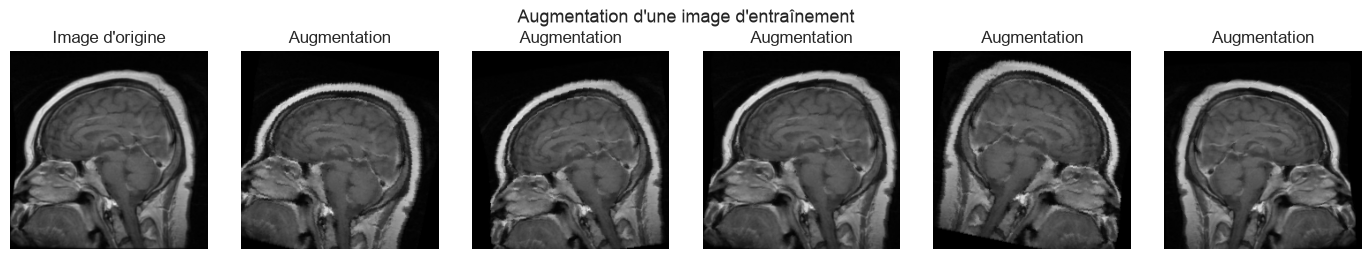

In [5]:
set_seed(TRAINING_SEED)
sample = images_of("strong", strong_label)
raw = sample.load(0)
figure, axes = plt.subplots(1, 6, figsize=(14, 2.6))
axes[0].imshow(raw[0], cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Image d'origine")
for axis in axes[1:]:
    axis.imshow(AUGMENT(raw)[0], cmap="gray", vmin=0, vmax=1)
    axis.set_title("Augmentation")
for axis in axes:
    axis.axis("off")
figure.suptitle("Augmentation d'une image d'entraînement", fontsize=13)
plt.tight_layout()
figure.savefig(FIGURES_DIR / "augmentation.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Modèle, entraînement et métriques

Le modèle est un **ResNet50 pré-entraîné sur ImageNet**, que l'on **ajuste** (*fine-tuning*) : toutes les couches sont gelées, sauf `layer4` (les derniers blocs convolutifs, qui captent les caractéristiques de haut niveau) et la **couche de classification**, remplacée par une couche linéaire à deux sorties (`normal`, `cancer`). `layer1` à `layer3` gardent les caractéristiques d'ImageNet, transférables. Le score d'une image est la probabilité de `cancer`.

Pendant l'entraînement, le réseau est en mode entraînement : les couches de normalisation par lot (*BatchNorm*) s'adaptent aux IRM. Les trois modèles utilisent exactement la même architecture.

In [6]:
def loader(name, labels, training, balanced=False, seed=0):
    """Lots d'un jeu de `indices`, avec ses classes (`labels`)."""
    positions = indices[name]
    return make_loader(
        manifest["filepath"].iloc[positions].tolist(),
        labels[positions].astype(int),
        training,
        balanced,
        seed,
    )

In [7]:
VALIDATION_LOADER = loader("validation", strong_label, training=False)
TEST_LOADER = loader("test", strong_label, training=False)


def train_a(seed):
    """Modèle A : labels forts seuls, arrêt anticipé."""
    model = create_model(seed, DEVICE)
    history, best = fit(
        model,
        loader("strong", strong_label, True, False, seed),
        VALIDATION_LOADER,
        MAX_EPOCHS,
        DEVICE,
        PATIENCE,
    )
    return model, history, best


def train_b(seed):
    """Modèle B : labels faibles seuls, nombre d'époques fixe."""
    model = create_model(seed, DEVICE)
    history, best = fit(
        model,
        loader("weak", weak_label, True, True, seed),
        VALIDATION_LOADER,
        WEAK_EPOCHS,
        DEVICE,
    )
    return model, history, best


def train_c(model_b, seed):
    """Modèle C : poursuite de B sur les labels forts, arrêt anticipé."""
    model = deepcopy(model_b)
    history, best = fit(
        model,
        loader("strong", strong_label, True, False, seed),
        VALIDATION_LOADER,
        MAX_EPOCHS,
        DEVICE,
        PATIENCE,
    )
    return model, history, best


def evaluate(model):
    """Métriques de validation et de test d'un modèle entraîné."""
    validation_labels, validation_scores, _ = predict(
        model, VALIDATION_LOADER, DEVICE
    )
    test_labels, test_scores, _ = predict(model, TEST_LOADER, DEVICE)
    return {
        "validation": classification_scores(
            validation_labels, validation_scores
        ),
        "test": classification_scores(test_labels, test_scores),
        "test_labels": test_labels.astype(int),
        "test_scores": test_scores,
    }

## 5. Modèle A : labels forts seuls

A entraîne `layer4` et la couche de classification sur les 68 images annotées de l'entraînement. L'entraînement s'arrête après 5 époques sans baisse de la perte de validation, et la meilleure époque est conservée.

In [8]:
set_seed(TRAINING_SEED)
total, trainable = count_parameters(create_model(TRAINING_SEED, DEVICE))
print(f"Paramètres totaux       : {total:>12,}")
print(f"Paramètres entraînables : {trainable:>12,} ({trainable / total:.1%})")
print(
    f"Paramètres gelés        : {total - trainable:>12,} "
    f"({(total - trainable) / total:.1%})"
)
model_a, history_a, best_epoch_a = train_a(TRAINING_SEED)
print(f"A : {len(history_a)} époques, meilleure époque {best_epoch_a}")

Paramètres totaux       :   23,512,130
Paramètres entraînables :   14,968,834 (63.7%)
Paramètres gelés        :    8,543,296 (36.3%)
A : 16 époques, meilleure époque 11


## 6. Modèles B et C : labels faibles, puis labels forts

**Phase 1.** B entraîne le même réseau sur les 1 194 images non annotées avec leur label faible, pendant 10 époques. Il est évalué seul, comme la consigne le demande.

**Phase 2.** C reprend B **tel qu'il est à la fin de la phase 1** et poursuit son entraînement sur les 68 images annotées, avec le même protocole que A (même optimiseur, même arrêt anticipé).

In [9]:
set_seed(TRAINING_SEED)
model_b, history_b, _ = train_b(TRAINING_SEED)
print(f"B : {len(history_b)} époques sur les labels faibles")

B : 10 époques sur les labels faibles


In [10]:
set_seed(TRAINING_SEED)
model_c, history_c, best_epoch_c = train_c(model_b, TRAINING_SEED)
print(
    f"C : {len(history_c)} époques sur les labels forts, meilleure époque {best_epoch_c}"
)

models = {"A": model_a, "B": model_b, "C": model_c}
histories = {"A": history_a, "B": history_b, "C": history_c}
best_epochs = {"A": best_epoch_a, "B": None, "C": best_epoch_c}

C : 8 époques sur les labels forts, meilleure époque 3


## 7. Courbes d'apprentissage

Chaque colonne montre un entraînement. En haut, la **perte** d'entraînement et de validation ; en bas, les **métriques de validation** à chaque époque. À droite, le modèle B (phase sur les labels faibles) est suivi du modèle C (phase sur les labels forts), séparés par un trait gris. Le trait vert marque la **meilleure époque** conservée pour la perte de validation.

La validation compte 14 images : ses courbes varient fortement d'une époque à l'autre.

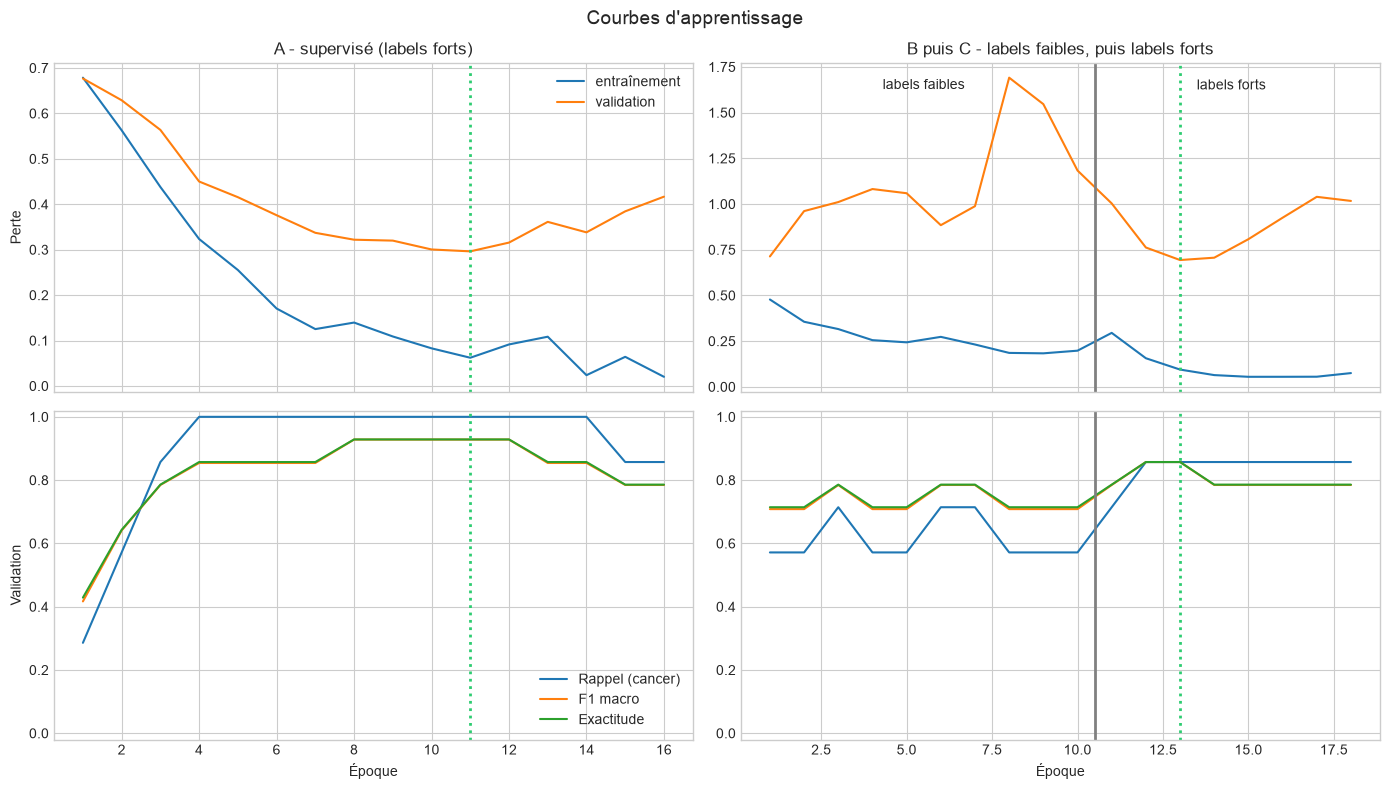

In [11]:
def plot_learning_curves(histories, best_epochs):
    """Perte et métriques de validation à chaque époque : A, puis B suivi de C."""
    figure, axes = plt.subplots(2, 2, figsize=(14, 8), sharex="col")

    # Colonne de gauche : A. Colonne de droite : B (labels faibles), puis C.
    offset = len(histories["B"])
    columns = [
        ("A - supervisé (labels forts)", histories["A"], 0, best_epochs["A"]),
        (
            "B puis C - labels faibles, puis labels forts",
            pd.concat(
                [
                    histories["B"],
                    histories["C"].assign(
                        epoch=histories["C"]["epoch"] + offset
                    ),
                ]
            ),
            1,
            None if best_epochs["C"] is None else best_epochs["C"] + offset,
        ),
    ]
    for title, history, column, best in columns:
        loss_axis, metric_axis = axes[0, column], axes[1, column]
        loss_axis.plot(
            history["epoch"], history["train_loss"], label="entraînement"
        )
        loss_axis.plot(
            history["epoch"], history["val_loss"], label="validation"
        )
        loss_axis.set_title(title)
        for metric in ("recall", "f1_macro", "accuracy"):
            metric_axis.plot(
                history["epoch"],
                history[f"val_{metric}"],
                label=METRIC_LABELS[metric],
            )
        metric_axis.set(xlabel="Époque", ylim=(-0.02, 1.02))
        for axis in (loss_axis, metric_axis):
            if column == 1:
                axis.axvline(offset + 0.5, color="grey", linewidth=2)
            if best is not None:
                axis.axvline(best, color="#2ecc71", linestyle=":", linewidth=2)
    axes[0, 1].text(
        offset / 2 + 0.5,
        axes[0, 1].get_ylim()[1] * 0.95,
        "labels faibles",
        ha="center",
        va="top",
    )
    axes[0, 1].text(
        offset + 0.5 + (len(histories["C"])) / 2,
        axes[0, 1].get_ylim()[1] * 0.95,
        "labels forts",
        ha="center",
        va="top",
    )
    axes[0, 0].set_ylabel("Perte")
    axes[1, 0].set_ylabel("Validation")
    axes[0, 0].legend()
    axes[1, 0].legend(loc="lower right")
    figure.suptitle("Courbes d'apprentissage", fontsize=14)
    plt.tight_layout()
    return figure


figure_curves = plot_learning_curves(histories, best_epochs)
figure_curves.savefig(
    FIGURES_DIR / "semi-courbes-apprentissage.png", dpi=120, bbox_inches="tight"
)
plt.show()

In [12]:
# Perte de validation au début, au minimum et à la fin de chaque phase.
rows = []
for name, label in (
    ("A", "A (labels forts)"),
    ("B", "B (phase faible)"),
    ("C", "C (labels forts)"),
):
    history = histories[name]
    rows.append(
        {
            "phase": label,
            "perte entraînement, première → dernière": (
                f"{history['train_loss'].iloc[0]:.2f} → "
                f"{history['train_loss'].iloc[-1]:.2f}"
            ),
            "perte validation, première → minimale → dernière": (
                f"{history['val_loss'].iloc[0]:.2f} → "
                f"{history['val_loss'].min():.2f} → "
                f"{history['val_loss'].iloc[-1]:.2f}"
            ),
            "rappel validation, première → dernière": (
                f"{history['val_recall'].iloc[0]:.2f} → "
                f"{history['val_recall'].iloc[-1]:.2f}"
            ),
        }
    )
display(pd.DataFrame(rows).set_index("phase"))

,"perte entraînement, première → dernière","perte validation, première → minimale → dernière","rappel validation, première → dernière"
phase,,,
A (labels forts),0.68 → 0.02,0.68 → 0.30 → 0.42,0.29 → 0.86
B (phase faible),0.48 → 0.20,0.71 → 0.71 → 1.18,0.57 → 0.57
C (labels forts),0.29 → 0.07,1.00 → 0.69 → 1.02,0.71 → 0.86


**Modèle A.** La perte d'entraînement tombe de 0,68 à 0,02. La perte de validation baisse jusqu'à 0,30 à l'époque 11 (meilleure époque conservée), puis remonte à 0,42 : l'entraînement s'arrête à l'époque 16. Le rappel de validation passe de 0,29 à 1,00 dès l'époque 4, puis redescend à 0,86.

**Phase sur les labels faibles (B).** La perte d'entraînement baisse de 0,48 à 0,20, mais la perte de validation, mesurée sur les labels forts, **monte** : de 0,71 à environ 1,7 à l'époque 8, puis 1,18 à la fin de la phase. Le rappel de validation reste entre 0,57 et 0,71 : le réseau apprend les labels faibles sans apprendre à détecter les cancers annotés.

**Phase sur les labels forts (C).** La perte de validation, qui valait 1,18 à la fin de la phase sur les labels faibles, vaut 1,00 après la première époque, puis descend à 0,69 à l'époque 3 de la phase (meilleure époque conservée, 8 époques au total), **contre 0,30 pour A**, puis remonte à 1,02. Le rappel de validation passe de 0,71 à 0,86.

## 8. Résultats

Le tableau donne les métriques de chaque modèle sur la **validation** (14 images, déjà utilisée pour l'arrêt anticipé de A et de C) et sur le **test** (15 images, lu une seule fois par modèle).

In [13]:
results = {name: evaluate(model) for name, model in models.items()}


def scores_table(results, part):
    """Métriques de chaque modèle sur `validation` ou `test`."""
    table = pd.DataFrame(
        {
            f"{name} - {CONDITIONS[name]}": results[name][part]
            for name in results
        }
    )
    return table.rename(index=METRIC_LABELS).T


print("Validation")
display(scores_table(results, "validation").round(3))
print("Test")
display(scores_table(results, "test").round(3))

for name, result in results.items():
    predicted = (result["test_scores"] >= DECISION_THRESHOLD).astype(int)
    print(f"\n{name} - {CONDITIONS[name]} (test)")
    print(
        classification_report(
            result["test_labels"],
            predicted,
            labels=[1, 0],
            target_names=["cancer", "normal"],
            zero_division=0,
        )
    )

Validation


,Rappel (cancer),Précision (cancer),F1 macro,Exactitude
A - supervisé (labels forts),1.000,0.875,0.928,0.929
B - faible (labels faibles),0.571,0.800,0.708,0.714
C - semi-supervisé (faibles puis forts),0.857,0.857,0.857,0.857


Test


,Rappel (cancer),Précision (cancer),F1 macro,Exactitude
A - supervisé (labels forts),0.750,1.0,0.866,0.867
B - faible (labels faibles),0.500,1.0,0.722,0.733
C - semi-supervisé (faibles puis forts),0.875,1.0,0.933,0.933



A - supervisé (labels forts) (test)
              precision    recall  f1-score   support

      cancer       1.00      0.75      0.86         8
      normal       0.78      1.00      0.88         7

    accuracy                           0.87        15
   macro avg       0.89      0.88      0.87        15
weighted avg       0.90      0.87      0.87        15


B - faible (labels faibles) (test)
              precision    recall  f1-score   support

      cancer       1.00      0.50      0.67         8
      normal       0.64      1.00      0.78         7

    accuracy                           0.73        15
   macro avg       0.82      0.75      0.72        15
weighted avg       0.83      0.73      0.72        15


C - semi-supervisé (faibles puis forts) (test)
              precision    recall  f1-score   support

      cancer       1.00      0.88      0.93         8
      normal       0.88      1.00      0.93         7

    accuracy                           0.93        15
   macr

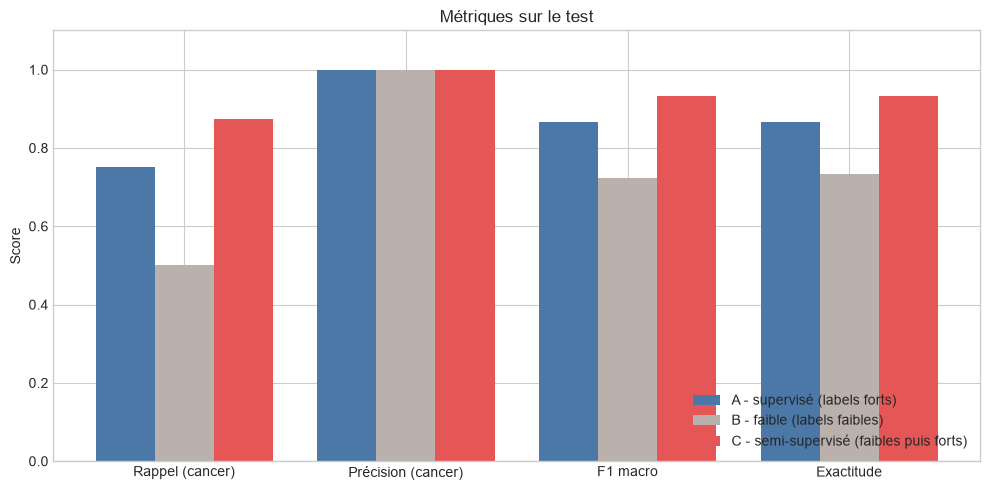

In [14]:
def plot_metrics(results):
    """Métriques de test des trois modèles, côte à côte."""
    figure, axis = plt.subplots(figsize=(10, 5))
    metrics = list(METRIC_LABELS)
    positions = np.arange(len(metrics))
    width = 0.8 / len(results)
    for shift, (name, result) in enumerate(results.items()):
        axis.bar(
            positions + (shift - (len(results) - 1) / 2) * width,
            [result["test"][metric] for metric in metrics],
            width,
            color=CONDITION_COLORS[name],
            label=f"{name} - {CONDITIONS[name]}",
        )
    axis.set(
        title="Métriques sur le test",
        xticks=positions,
        xticklabels=[METRIC_LABELS[metric] for metric in metrics],
        ylabel="Score",
        ylim=(0, 1.1),
    )
    axis.legend(loc="lower right")
    plt.tight_layout()
    return figure


figure_metrics_test = plot_metrics(results)
figure_metrics_test.savefig(
    FIGURES_DIR / "semi-metriques-test.png", dpi=120, bbox_inches="tight"
)
plt.show()

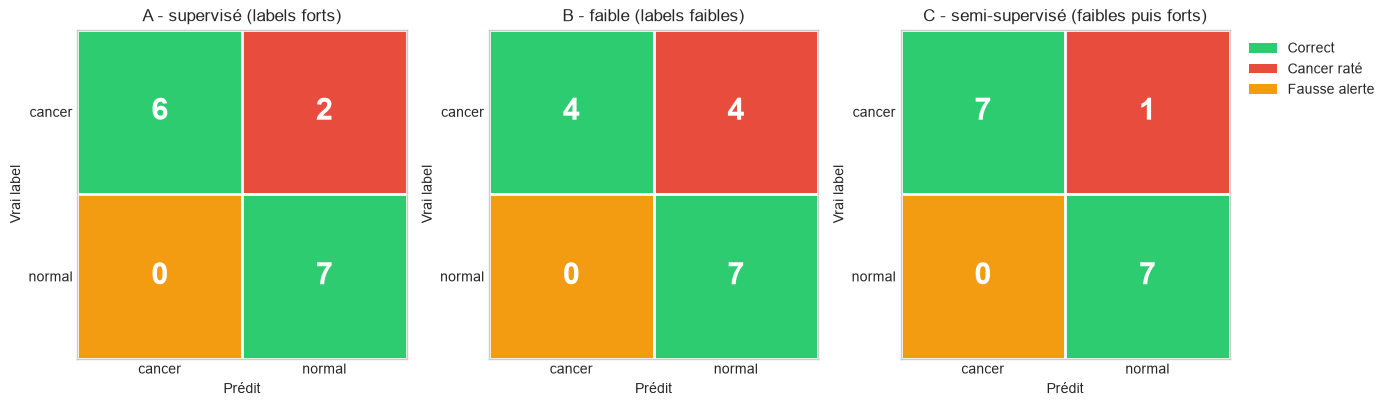

In [15]:
CONFUSION_COLORS = (("#2ecc71", "#e74c3c"), ("#f39c12", "#2ecc71"))
CONFUSION_LEGEND = [
    Patch(facecolor="#2ecc71", label="Correct"),
    Patch(facecolor="#e74c3c", label="Cancer raté"),
    Patch(facecolor="#f39c12", label="Fausse alerte"),
]


def plot_confusions(results):
    """Matrices de confusion des trois modèles sur le test."""
    figure, axes = plt.subplots(1, 3, figsize=(14, 5))
    for axis, (name, result) in zip(axes, results.items(), strict=True):
        predicted = (result["test_scores"] >= DECISION_THRESHOLD).astype(int)
        matrix = confusion_matrix(
            result["test_labels"], predicted, labels=[1, 0]
        )
        for row in range(2):
            for column in range(2):
                axis.add_patch(
                    plt.Rectangle(
                        (column - 0.5, row - 0.5),
                        1,
                        1,
                        facecolor=CONFUSION_COLORS[row][column],
                        edgecolor="white",
                        linewidth=2,
                    )
                )
                axis.text(
                    column,
                    row,
                    matrix[row, column],
                    ha="center",
                    va="center",
                    fontsize=22,
                    fontweight="bold",
                    color="white",
                )
        axis.set(
            xlim=(-0.5, 1.5),
            ylim=(1.5, -0.5),
            xticks=[0, 1],
            yticks=[0, 1],
            xticklabels=["cancer", "normal"],
            yticklabels=["cancer", "normal"],
            xlabel="Prédit",
            ylabel="Vrai label",
            title=f"{name} - {CONDITIONS[name]}",
        )
        axis.set_aspect("equal")
        axis.grid(False)
    axes[-1].legend(
        handles=CONFUSION_LEGEND, loc="upper left", bbox_to_anchor=(1.02, 1)
    )
    plt.tight_layout()
    return figure


figure_confusions = plot_confusions(results)
figure_confusions.savefig(
    FIGURES_DIR / "semi-matrices-confusion.png", dpi=120, bbox_inches="tight"
)
plt.show()

**Test.** C obtient le meilleur rappel de `cancer` (0,875 : 7 cancers détectés sur 8, un raté), contre 0,75 pour A (2 ratés) et 0,50 pour B (4 ratés). Les trois modèles ont une précision de 1,00 : aucune fausse alerte. Le F1 macro vaut 0,93 pour C, 0,87 pour A et 0,72 pour B.

**Validation.** Le sens s'inverse : A a un rappel de 1,00 et un F1 macro de 0,93, contre 0,86 pour C et 0,71 pour B. La validation a pourtant servi à l'arrêt anticipé de A et de C, et ne compte que 14 images.

L'écart entre A et C est d'**une image** dans chaque jeu, dans un sens sur le test et dans l'autre sur la validation. B, entraîné sur les seuls labels faibles, est le moins bon sur les deux jeux.

## 9. Suivi des expériences

Chaque modèle est un **run MLflow** : ses réglages, ses jeux d'entraînement, de validation et de test, ses métriques, la **perte et les métriques de validation de chaque époque** (pour retracer les courbes d'apprentissage), la figure des courbes et le modèle lui-même.

In [16]:
TRAINING_SETS = {"A": ("strong",), "B": ("weak",), "C": ("weak", "strong")}


def load_example(position):
    """Image prétraitée de la position donnée, en tableau NumPy."""
    with Image.open(manifest["filepath"].iloc[position]) as image:
        return preprocess_gray(image).numpy()


# Deux images : avec une seule, `torch.export` fixerait la taille de lot à 1.
MODEL_INPUT_EXAMPLE = np.stack([load_example(0), load_example(1)])


def dataset_table(name):
    """Table d'un jeu pour MLflow : `image_id` et label (fort ou faible)."""
    rows = manifest.iloc[indices[name]]
    if name == "weak":
        classes = np.where(weak_label[indices[name]] == 1, "cancer", "normal")
        return rows[["image_id"]].assign(weak_label=classes)
    return rows[["image_id", "subset", "label"]]


def log_run(
    condition, seed, histories, best_epoch, scores, model=None, figure=None
):
    """Enregistre le run d'un modèle (réglages, jeux, courbes, métriques)."""
    with start_run(
        f"{condition}-seed{seed}",
        phase="semi-supervised",
        notebook=NOTEBOOK,
        manifest_path=MANIFEST_PATH,
        seed=seed,
        description=f"Modèle {condition} - {CONDITIONS[condition]}, graine {seed}",
    ):
        log_params(
            {
                "condition": condition,
                "backbone": MODEL_NAME,
                "trained_layers": "layer4 + couche finale",
                "learning_rate": LEARNING_RATE,
                "batch_size": TRAIN_BATCH_SIZE,
                "weak_epochs": WEAK_EPOCHS,
                "max_epochs": MAX_EPOCHS,
                "patience": PATIENCE,
                "decision_threshold": DECISION_THRESHOLD,
                "augmentation": "flip, rotation 15, translation 5 %, zoom 5 %",
            }
        )
        for name in (*TRAINING_SETS[condition], "validation", "test"):
            training = name in ("strong", "weak")
            log_dataset(
                dataset_table(name),
                name=f"train-{name}" if training else name,
                context="training" if training else name,
                source="data/interim/manifest.csv",
                targets="weak_label" if name == "weak" else "label",
            )
        step = 0
        for history in histories:
            for _, row in history.iterrows():
                step += 1
                log_metrics(
                    {
                        key: row[key]
                        for key in history.columns
                        if key != "epoch"
                    },
                    step=step,
                )
        log_metrics(
            {
                **{f"val_{k}": v for k, v in scores["validation"].items()},
                **{f"test_{k}": v for k, v in scores["test"].items()},
                "best_epoch": best_epoch if best_epoch is not None else 0,
                "epochs_run": sum(len(history) for history in histories),
            }
        )
        if figure is not None:
            log_figure(figure, "semi-courbes-apprentissage.png")
        if model is not None:
            log_pytorch_model(
                deepcopy(model).cpu(), f"model-{condition}", MODEL_INPUT_EXAMPLE
            )

In [17]:
HISTORIES_OF = {"A": ("A",), "B": ("B",), "C": ("B", "C")}
for name in "ABC":
    log_run(
        name,
        TRAINING_SEED,
        [histories[key] for key in HISTORIES_OF[name]],
        best_epochs[name],
        results[name],
        model=models[name],
        figure=figure_curves,
    )

## 10. Limites et décision

### Ce que montrent les résultats

- **Sur le test, C fait un peu mieux que A.** Il détecte un cancer de plus (rappel de 0,875 contre 0,75), sans fausse alerte, avec un F1 macro de 0,93 contre 0,87. Le sens est celui attendu d'une approche semi-supervisée.
- **Sur la validation, c'est A qui fait un peu mieux** (rappel de 1,00 contre 0,86), d'une image aussi. L'avantage de C sur le test tient à une image et n'est pas démontré.
- **Les labels faibles seuls ne suffisent pas.** B est le moins bon des trois (rappel de 0,50 sur le test, 0,57 sur la validation) : sa perte de validation monte pendant la phase sur les labels faibles, le réseau apprend des labels en partie faux.
- **La phase sur les labels forts répare ce modèle sans atteindre la perte de A** (0,69 contre 0,30 à la meilleure époque).

### Limites du protocole

- **Test de 15 images** (8 `cancer`, 7 `normal`) : un cancer raté représente 12,5 points de rappel. Un écart d'une image entre deux modèles n'est pas significatif.
- **Labels faibles de qualité limitée.** Ils viennent d'un clustering dont l'exactitude sur les images annotées jamais vues est de 0,60 à 0,71 (notebook `03.01`), et dont les clusters suivent en partie le plan de coupe. Le réseau apprend ces labels, pas la pathologie.
- **Information déjà contenue dans les features.** Les labels faibles sont calculés sur les mêmes features ResNet50 que celles que le CNN utilise : la phase sur les labels faibles peut se contenter de reproduire la partition de K-Means, sans information nouvelle.
- **Ordre imposé par le protocole.** Les labels faibles passent avant les labels forts : la phase la moins fiable vient en premier et la phase fiable doit la rattraper.
- **Peu d'images annotées.** L'entraînement fort ne compte que 68 images et la validation, qui règle l'arrêt anticipé de A et de C, que 14 : ses courbes sont bruitées.
- **Un seul entraînement par modèle.** Les résultats dépendent de la graine, et un seul découpage est utilisé : des images très proches (même série, même patient) peuvent se trouver de part et d'autre du découpage.
- **Réglages non optimisés.** Ils sont fixés d'avance et jamais ajustés, volontairement : sur 15 images de test, une recherche de réglages reviendrait à les ajuster sur le test.

### Décision

Sur ces données, un CNN entraîné d'abord sur les labels faibles, puis sur les labels forts, détecte **un cancer de plus** qu'un CNN entraîné sur les 68 labels forts seuls sur le test, et un de moins sur la validation : la différence est **dans le sens attendu mais trop petite pour être démontrée**. Elle suppose en outre de passer 10 époques sur 1 194 images de labels faibles.

Pour savoir si l'écart est réel, il faudrait répéter les entraînements sur plusieurs graines et plusieurs découpages. Une méthode qui n'a pas besoin d'un clustering pour fabriquer ses labels, par exemple un auto-entraînement à partir des seuls labels forts, reste à tester.